TASK 1

IRIS FLOWER CLASSIFICATION

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris

In [24]:
iris = load_iris()

In [25]:
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["species"]= iris.target
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


Exploratory Data Analysis (EDA)

In [26]:
print("Dataset Shape:", df.shape)

Dataset Shape: (150, 5)


In [27]:
df.dtypes

,0
sepal length (cm),float64
sepal width (cm),float64
petal length (cm),float64
petal width (cm),float64
species,int64


In [28]:
df.isnull().sum()

,0
sepal length (cm),0
sepal width (cm),0
petal length (cm),0
petal width (cm),0
species,0


In [29]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [30]:
df['species'].value_counts()

,count
species,
0,50
1,50
2,50


Visualizations

In [31]:
df["species"]= df["species"].map({ 0: "Setosa", 1: "Versicolor", 2: "Virginica"})
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
3,4.6,3.1,1.5,0.2,Setosa
4,5.0,3.6,1.4,0.2,Setosa


Pairplot


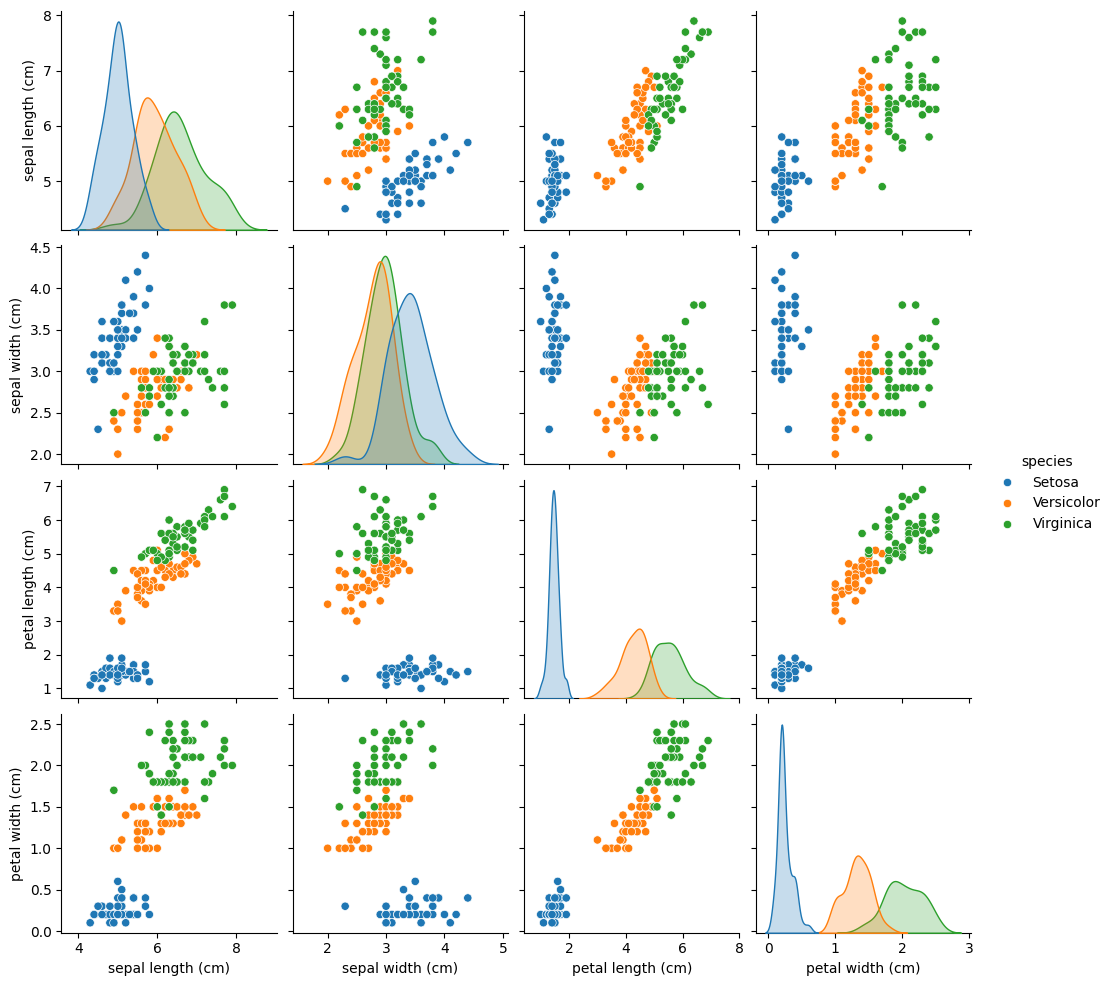

In [32]:
sns.pairplot(df, hue="species")
plt.show()

Boxplot

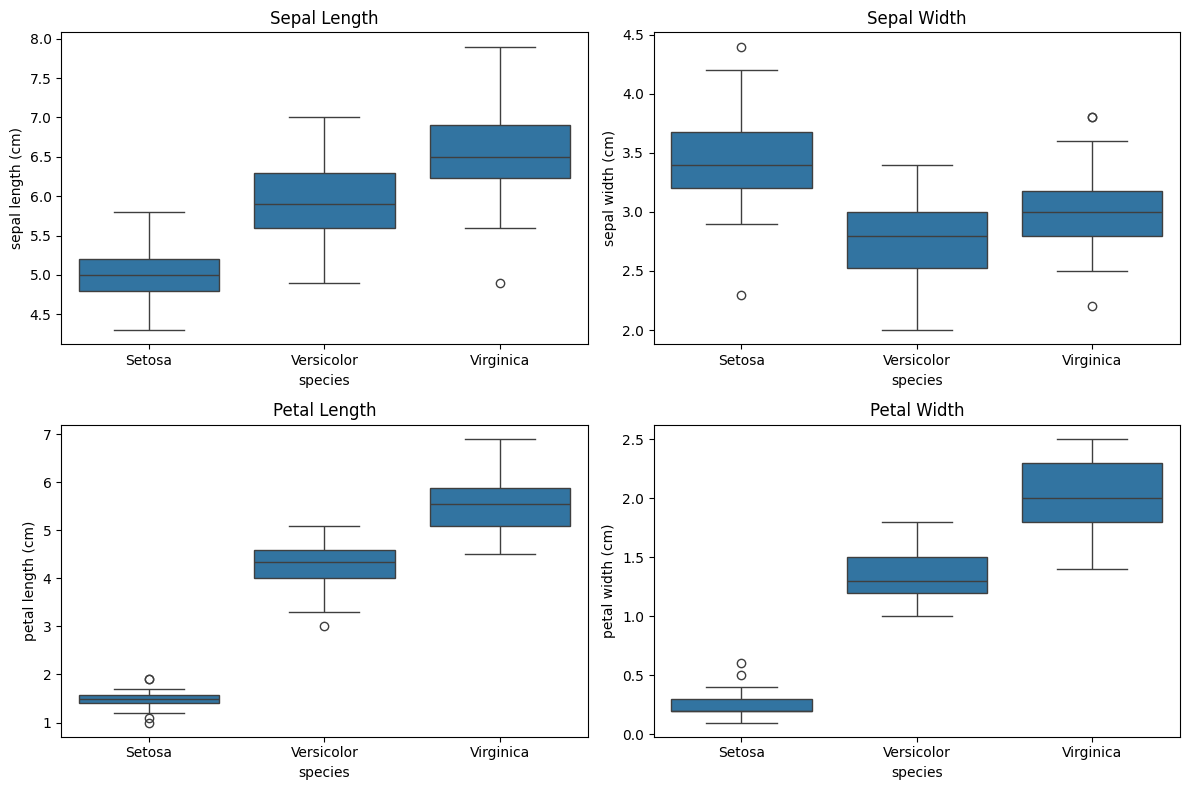

In [33]:
plt.figure(figsize=(12, 8))

plt.subplot(2,2,1)
sns.boxplot(data=df, x="species", y="sepal length (cm)")
plt.title("Sepal Length")

plt.subplot(2,2,2)
sns.boxplot( data=df,x="species", y="sepal width (cm)")
plt.title("Sepal Width")

plt.subplot(2,2,3)
sns.boxplot(data=df, x="species", y="petal length (cm)")
plt.title("Petal Length")

plt.subplot(2,2,4)
sns.boxplot(data=df, x="species", y="petal width (cm)")
plt.title("Petal Width")

plt.tight_layout()
plt.show()


Feature selection

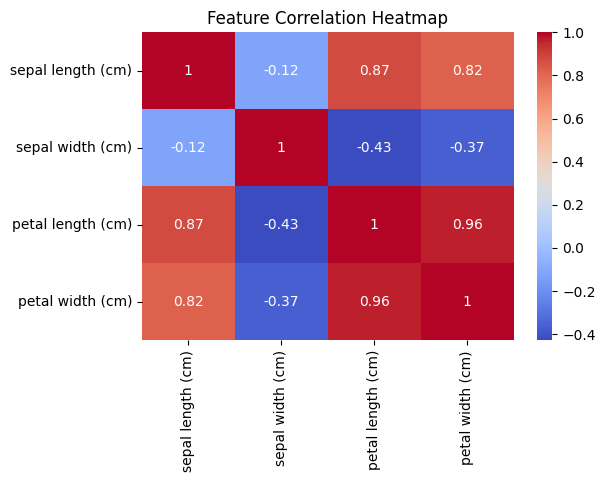

In [34]:
features = iris.feature_names
correlation = df[features].corr()
plt.figure(figsize=(6, 4))
sns.heatmap(correlation, annot=True, cmap="coolwarm")

plt.title("Feature Correlation Heatmap")
plt.show()

train/test split


In [51]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

In [52]:
X = df.drop('species', axis=1)
y = df['species']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (120, 4)
Testing data: (30, 4)


Logistic Regression

In [53]:
from sklearn.linear_model import LogisticRegression
model1 = LogisticRegression(max_iter=200)
model1.fit(X_train, y_train)
y_pred1 = model1.predict(X_test)

K-Nearest Neighbours

In [54]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
y_pred_knn = knn.predict(X_test_scaled)
accuracy2 = accuracy_score(y_test, y_pred_knn)

Decision Tree Model

In [55]:
from sklearn.tree import DecisionTreeClassifier
model3 = DecisionTreeClassifier(random_state=42)
model3.fit(X_train, y_train)
y_pred3 = model3.predict(X_test)

Evalution of models

In [56]:
from sklearn.metrics import accuracy_score
accuracy1 = accuracy_score(y_test, y_pred1)
accuracy2 = accuracy_score(y_test, y_pred2)
accuracy3 = accuracy_score(y_test, y_pred3)

print("Logistic Regression Accuracy:", accuracy1)
print("KNN Accuracy:", accuracy2)
print("Decision Tree Accuracy:", accuracy3)

Logistic Regression Accuracy: 0.9666666666666667
KNN Accuracy: 0.9333333333333333
Decision Tree Accuracy: 0.9333333333333333


Confusion matrix

In [57]:
from sklearn.metrics import confusion_matrix
cm1 = confusion_matrix(y_test, y_pred1)
print("Logistic Regression Confusion Matrix")
print(cm1)

cm2 = confusion_matrix(y_test, y_pred2)
print("KNN Confusion Matrix")
print(cm2)

cm3 = confusion_matrix(y_test, y_pred3)
print("Decision Tree Confusion Matrix")
print(cm3)

Logistic Regression Confusion Matrix
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]
KNN Confusion Matrix
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]
Decision Tree Confusion Matrix
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


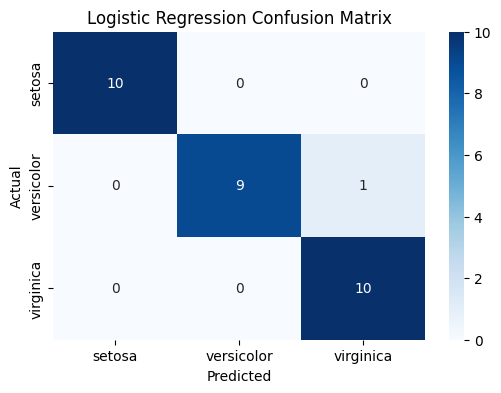

In [58]:
plt.figure(figsize=(6,4))
sns.heatmap(cm1, annot=True, fmt="d", cmap="Blues",
              xticklabels=iris.target_names,
              yticklabels=iris.target_names)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

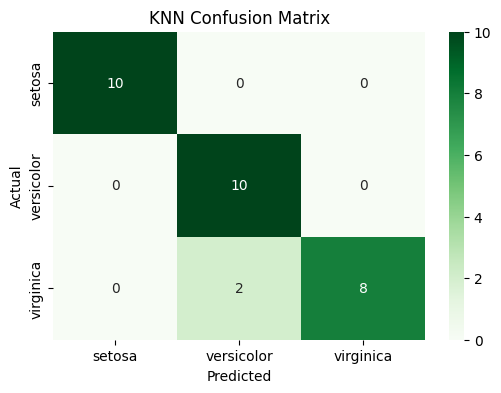

In [59]:
plt.figure(figsize=(6,4))
sns.heatmap(cm2, annot=True, fmt="d", cmap="Greens",
              xticklabels=iris.target_names,
              yticklabels=iris.target_names)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("KNN Confusion Matrix")
plt.show()

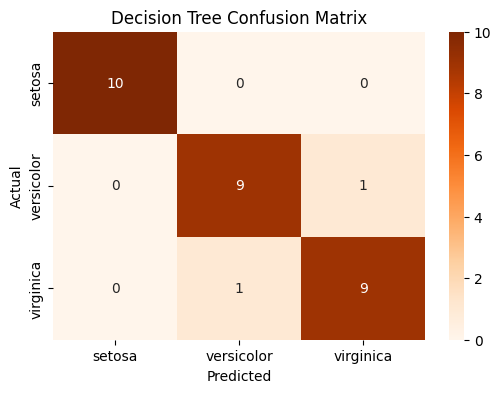

In [60]:
plt.figure(figsize=(6,4))
sns.heatmap(cm3, annot=True, fmt="d", cmap="Oranges",
              xticklabels=iris.target_names,
              yticklabels=iris.target_names)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree Confusion Matrix")
plt.show()

Classification report

In [61]:
from sklearn.metrics import classification_report
print("Logistics Regression report")
print(classification_report(y_test, y_pred1, target_names=iris.target_names))

print("Knn Report")
print(classification_report(y_test, y_pred2, target_names=iris.target_names))

print("Decision Tree Report")
print(classification_report(y_test, y_pred3, target_names=iris.target_names))

Logistics Regression report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

Knn Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30

Decision Tree Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica   

Compare & select the best model

In [62]:
print("Logistic Regression:", accuracy1)
print("KNN:", accuracy2)
print("Decision Tree:", accuracy3)

if accuracy1 == accuracy2 == accuracy3:
    print("All three models have equal accuracy")

elif accuracy1 >= accuracy2 and accuracy1 >= accuracy3:
    print("Best Model: Logistic Regression")

elif accuracy2 >= accuracy1 and accuracy2 >= accuracy3:
    print("Best Model: KNN")

else:
    print("Best Model: Decision Tree")

Logistic Regression: 0.9666666666666667
KNN: 0.9333333333333333
Decision Tree: 0.9333333333333333
Best Model: Logistic Regression


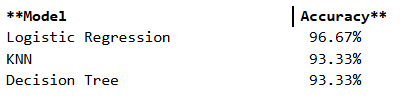

## Best Performing Model

The performance of Logistic Regression, K-Nearest Neighbors (KNN), and Decision Tree was compared using accuracy scores.
- Logistic Regression: 96.67%
- KNN: 93.33%
- Decision Tree: 93.33%
Logistic Regression achieved the highest accuracy of 96.67%, making it the best-performing model among the three classifiers. It correctly classified 29 out of 30 test samples.

Selected Model: Logistic Regression

## Conclusion
* The Iris dataset was successfully analysed and visualized using Python.



* Three classification models were trained and evaluated.



* Logistic Regression achieved the highest accuracy of 96.67%, making it the best-performing model.



The project provided practical understanding of data analysis, visualization, and machine learning classification.